In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
df = pd.read_csv("../data/processed/cleaned_data.csv",
                 parse_dates=["StartDatetime", "EndDatetime", "StartDay", "EndDay"])
for col in ["UserID", "ChargerID", "ChargerCompany", "ChargerType"]:
    df[col] = df[col].astype("category")
print(df.shape)

(72843, 13)


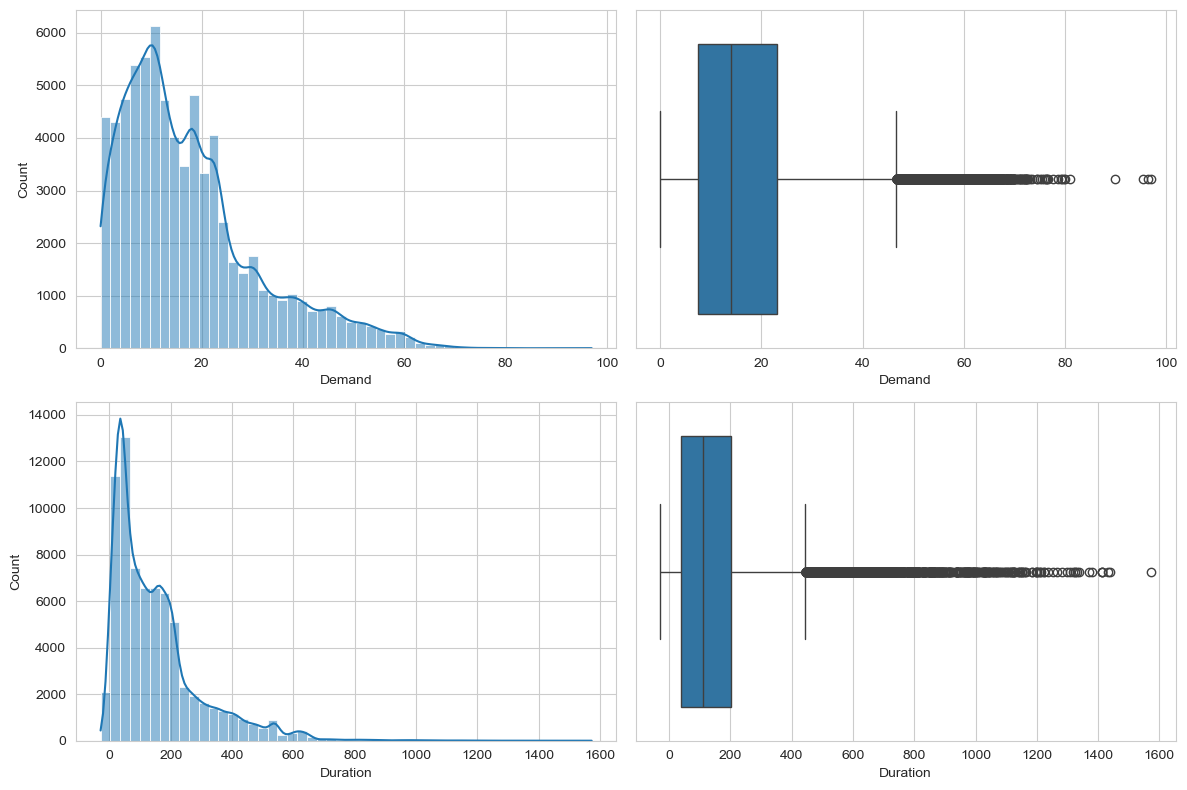

Skew: 1.189932634395281 1.9205978319253845


In [2]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df["Demand"], bins=50, kde=True, ax=ax[0, 0])
sns.boxplot(x=df["Demand"], ax=ax[0, 1])
sns.histplot(df["Duration"], bins=50, kde=True, ax=ax[1, 0])
sns.boxplot(x=df["Duration"], ax=ax[1, 1])
plt.tight_layout(); plt.show()

print("Skew:", df["Demand"].skew(), df["Duration"].skew())

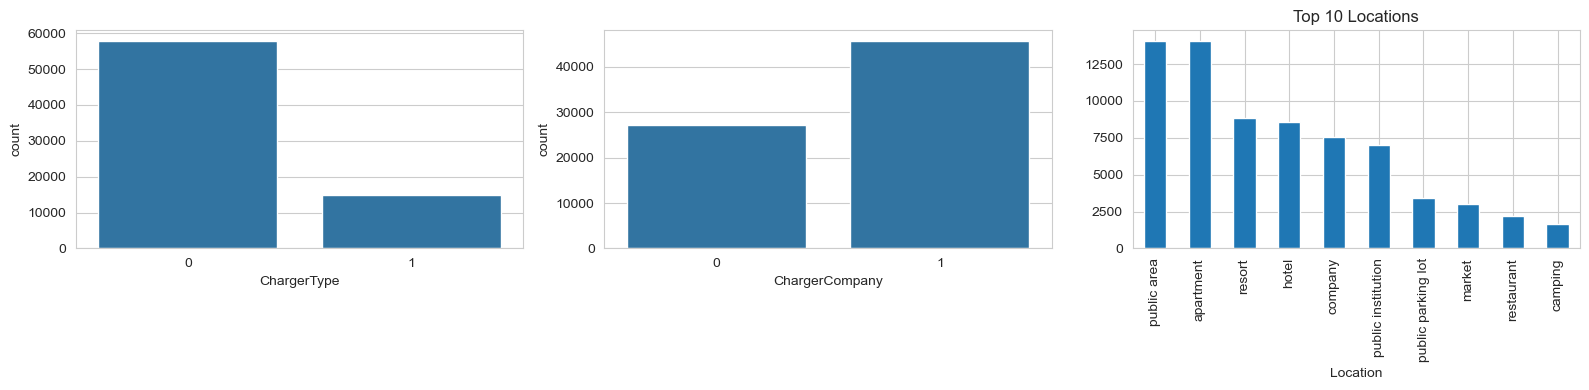

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="ChargerType", data=df, ax=ax[0])
sns.countplot(x="ChargerCompany", data=df, ax=ax[1])
df["Location"].value_counts().head(10).plot.bar(ax=ax[2], title="Top 10 Locations")
plt.tight_layout(); plt.show()

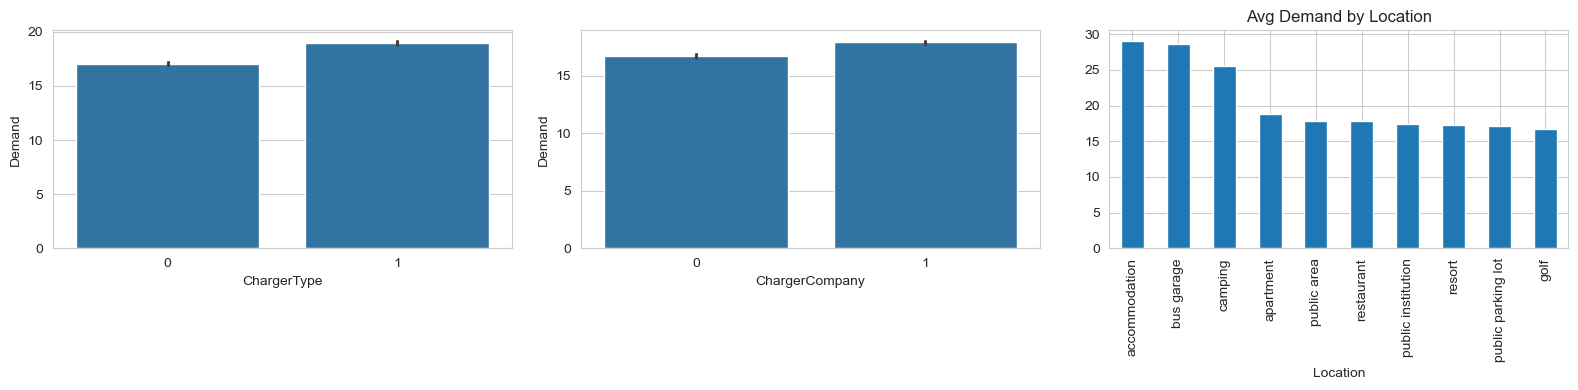

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(x="ChargerType", y="Demand", data=df, ax=ax[0])
sns.barplot(x="ChargerCompany", y="Demand", data=df, ax=ax[1])
df.groupby("Location")["Demand"].mean().sort_values(ascending=False).head(10).plot.bar(ax=ax[2], title="Avg Demand by Location")
plt.tight_layout(); plt.show()

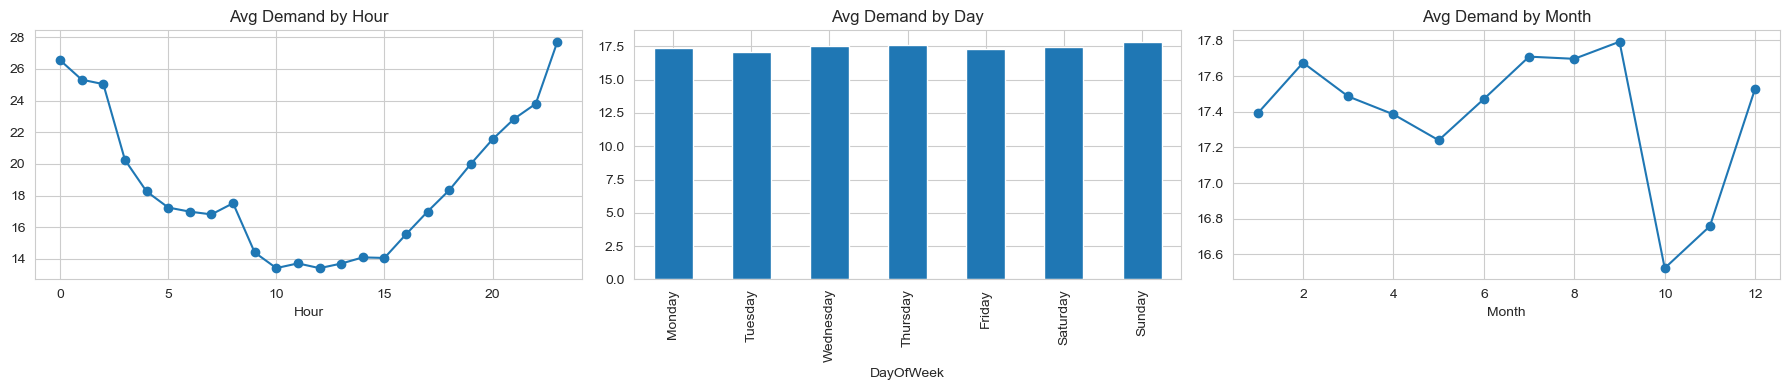

In [5]:
df["Hour"] = df["StartDatetime"].dt.hour
df["DayOfWeek"] = df["StartDatetime"].dt.day_name()
df["Month"] = df["StartDatetime"].dt.month

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
df.groupby("Hour")["Demand"].mean().plot(ax=ax[0], marker="o", title="Avg Demand by Hour")
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df.groupby("DayOfWeek")["Demand"].mean().reindex(order).plot.bar(ax=ax[1], title="Avg Demand by Day")
df.groupby("Month")["Demand"].mean().plot(ax=ax[2], marker="o", title="Avg Demand by Month")
plt.tight_layout(); plt.show()

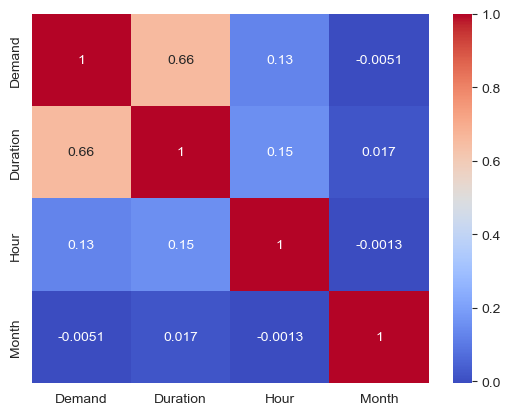

In [6]:
sns.heatmap(df[["Demand", "Duration", "Hour", "Month"]].corr(), annot=True, cmap="coolwarm")
plt.show()

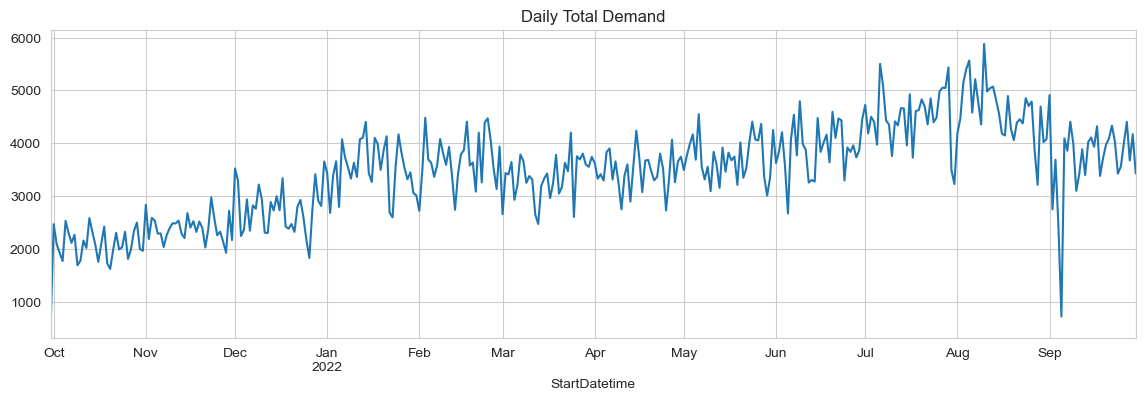

In [7]:
df.set_index("StartDatetime")["Demand"].resample("D").sum().plot(figsize=(14, 4), title="Daily Total Demand")
plt.show()